# 02.02 — Analyser télémétrie et progression RL

Analyse hors ligne les sessions `telemetry.jsonl` et les journaux PPO. Aucune commande envoyée au jeu.

In [1]:
from pathlib import Path
import sys
CWD=Path.cwd().resolve()
REPO=next((p for p in [CWD,*CWD.parents] if (p/'assetto_corsa_gym'/'assetto_corsa_gym'/'AssettoCorsaPlugin').is_dir()),None)
if REPO is None:
    raise FileNotFoundError('Ouvrir la racine IA_projet_Ouarti_ds_github ou un sous-dossier dans VS Code.')
PROJECT=REPO/'Code'
GYM_ROOT=REPO/'assetto_corsa_gym'/'assetto_corsa_gym'
assert PROJECT.is_dir(), 'Dossier Code introuvable'
if sys.version_info[:2] != (3,9):
    raise RuntimeError('Selectionner le kernel Python 3.9.13 dans VS Code. Actuel : '+sys.version)
for name in ['datasets','models','reports']:
    (PROJECT/name).mkdir(parents=True, exist_ok=True)
print('Depot :',REPO,'\nCode :',PROJECT,'\nPython :',sys.executable)

Depot : C:\Users\elkat\Documents\Github\IA_projet_Ouarti_ds_github 
Code : C:\Users\elkat\Documents\Github\IA_projet_Ouarti_ds_github\Code 
Python : c:\Users\elkat\AppData\Local\Programs\Python\Python39\python.exe


Sessions de telemetrie disponibles : 2
Session : session_20261116_201248 - paquets : 1012 - colonnes : 93


,Dy_fl,fr_damper_linear_potentiometer,wheel_speed_fl,LastFF,accelY,accelX,steps,angular_velocity_x,angular_velocity_y,angular_velocity_z,...,tyre_slip_ratio_fr,fl_wheel_load,fl_damper_linear_potentiometer,fr_tire_temperature_core,packetId,tyre_slip_ratio_fl,tyreContactHeading_RR_z,tyreContactHeading_RR_x,tyreContactHeading_RR_y,_received_unix
0,1.131114,0.077915,3.775616e-38,0.000098,0.0,0.0,1,-3.443108e-07,0.00001,-3.884746e-07,...,-0.000088,3333.729492,0.077581,80.0,7527,-0.000086,0.634999,-0.772351,0.015811,1.794856e+09
1,1.131099,0.077917,3.775616e-38,0.000098,0.0,0.0,2,-2.939252e-06,0.00001,-3.085018e-06,...,-0.000069,3333.972900,0.077569,80.0,7531,-0.000067,0.634999,-0.772351,0.015811,1.794856e+09
2,1.131130,0.077915,3.775616e-38,0.000098,0.0,0.0,3,-1.378042e-06,0.00001,-1.459891e-06,...,-0.000079,3333.501953,0.077570,80.0,7535,-0.000077,0.635000,-0.772350,0.015811,1.794856e+09


Frequence mediane recue : 38.04 Hz


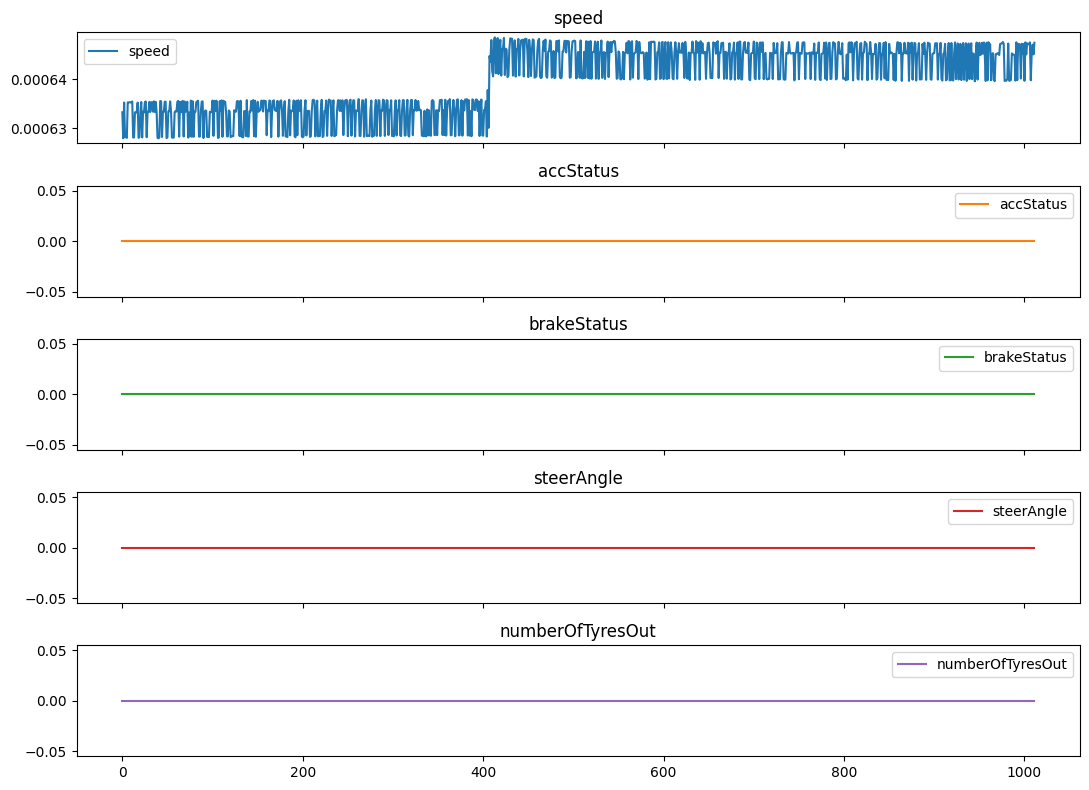

In [2]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
files=sorted((PROJECT/'datasets').glob('session_*/telemetry.jsonl'))
print('Sessions de telemetrie disponibles :',len(files))
if files:
    source=files[-1]
    with source.open(encoding='utf8') as f:
        records=[json.loads(line) for line in f if line.strip()]
    df=pd.DataFrame(records)
    if df.empty:raise RuntimeError('Session vide: '+str(source))
    print('Session :',source.parent.name,'- paquets :',len(df),'- colonnes :',len(df.columns))
    display(df.head(3))
    axis='timestamp_unix' if 'timestamp_unix' in df else '_received_unix'
    if axis in df:
        ts=pd.to_numeric(df[axis],errors='coerce')
        print('Frequence mediane recue :',round(1/ts.diff().dropna().median(),2),'Hz')
    fields=[x for x in ['speed','accStatus','brakeStatus','steerAngle','numberOfTyresOut'] if x in df]
    if fields:
        df[fields].apply(pd.to_numeric,errors='coerce').plot(subplots=True,figsize=(11,8),title=fields)
        plt.tight_layout();plt.show()
else:
    print('Aucune session: executer 01_Enregistrer_Session.ipynb ou 04_Capturer_Images.ipynb')

In [3]:
from pathlib import Path
for log in sorted((PROJECT/'reports').glob('**/ppo_steps.jsonl'))[-5:]:
    with log.open(encoding='utf8') as f:
        rows=[json.loads(l) for l in f if l.strip()]
    if not rows:continue
    train=pd.DataFrame(rows)
    print('Journal PPO :',log,'steps=',len(train))
    if 'reward' in train:
        train['reward'].rolling(100,min_periods=1).mean().plot(figsize=(11,3),
                      title='Recompense PPO, moyenne mobile (100 transitions)')
        plt.xlabel('Transition');plt.ylabel('Recompense');plt.show()
    for col in ['offtrack','collision','lap_finished']:
        if col in train:print(col,':',int(train[col].fillna(False).sum()))